#### This is a dataset consisting of restaurant reviews. Your goal is to predict the `stars` column.
Adapted from Katie Sylvia

#### Imports

In [2]:
import numpy as np
import pandas as pd       
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression

import nltk
from sklearn.feature_extraction.text import CountVectorizer
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('data/restaurant_reviews.csv', index_col = 0)

In [4]:
# info 
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10000 entries, 0 to 9999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   stars   10000 non-null  int64 
 1   text    10000 non-null  object
dtypes: int64(1), object(1)
memory usage: 234.4+ KB


In [5]:
df.head()

,stars,text
0,5,My wife took me here on my birthday for breakf...
1,5,I have no idea why some people give bad review...
2,4,love the gyro plate. Rice is so good and I als...
3,5,"Rosie, Dakota, and I LOVE Chaparral Dog Park!!..."
4,5,General Manager Scott Petello is a good egg!!!...


In [6]:
df = df.sample(4000, random_state=404)

#### Check baseline

In [7]:
# Vals
df['stars'].value_counts(normalize=True)

stars
4    0.35250
5    0.33400
3    0.15600
2    0.08825
1    0.06925
Name: proportion, dtype: float64

In [8]:
# Map
df['stars'] = df['stars'].map({1:'1 star', 2:'2 stars', 3:'3 stars', 4:'4 stars', 5:'5 stars'})

#### Sentiment analysis

In [9]:
# Initialize VADER
analyzer = SentimentIntensityAnalyzer()

def get_sentiment_score(sentence):
    scores = analyzer.polarity_scores(sentence)
    return scores['compound']
    # Compound score is a normalized score [-1, 1]

In [10]:
get_sentiment_score("I love food!")

0.6696

What if I wanted to include the sentiment score as a feature in my model?

In [11]:
# Add col
df['sentiment'] = df['text'].apply(lambda x:get_sentiment_score(x))

<AxesSubplot:>

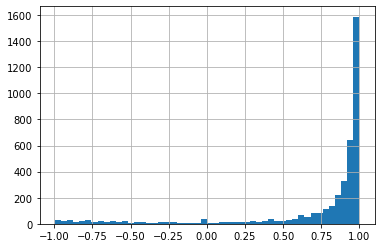

In [16]:
# Hist

df['sentiment']
df['sentiment'].hist(bins=50)

In [17]:
get_sentiment_score("I got sick! The food was on fire")

-0.7177

In [18]:
get_sentiment_score("sick burrito! The food was fire")

-0.7177

In [ ]:
# use your background knowledge

In [22]:
analyzer.lexicon['fire'] = .2

In [21]:
analyzer.lexicon['sick']

-2.3

[huggingface](https://huggingface.co/cardiffnlp/twitter-roberta-base)

In [ ]:
# Twitter model?
# For very niche tasks - look for models that were trained on your text! 

#### Train Test Split

In [23]:
X = df[['text', 'sentiment']]
y = df['stars']

In [24]:
# tts
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=404)

In [25]:
X.head()

,text,sentiment
1860,Stopped in and tried both their sweet potato f...,0.9371
4182,Outside atmosphere was really nice. This was m...,0.9545
8726,Zipps is a rocking place with TV screens in al...,0.9544
1892,OVERPRICED & DECEITFUL & RUDE!\r\n\r\nI should...,0.6934
8044,It's 1961 and we're having lunch in the courty...,0.9983


#### Pipeline

In [32]:
# Columntransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('text_vectorizer', CountVectorizer(stop_words='english', min_df=.1, max_df=.8), 'text')
    ],
    remainder = 'passthrough'
)

In [33]:
# Pipeline
pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('logreg', LogisticRegression(max_iter=1000))
])

In [34]:
# Fit 
pipe.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('text_vectorizer',
                                                  CountVectorizer(max_df=0.8,
                                                                  min_df=0.1,
                                                                  stop_words='english'),
                                                  'text')])),
                ('logreg', LogisticRegression(max_iter=1000))])

My `text` column was passed through my preprocessor, and my `sentiment` column was passed through unaltered as the remainder. 

#### Score on training and testing set

In [35]:
# Score
pipe.score(X_train, y_train), pipe.score(X_test, y_test)

(0.4876666666666667, 0.473)

It looks a little overfit! We could try reducing dimensionality:

- max_features
- min_df
- max_df

In [37]:
# labels = []

# Generate predictions on the test set
y_pred = pipe.predict(X_test)

# Classification report
report = classification_report(y_test, y_pred)

# Print the report
print(report)

              precision    recall  f1-score   support

      1 star       0.47      0.48      0.48        73
     2 stars       0.41      0.15      0.22        87
     3 stars       0.28      0.12      0.16       147
     4 stars       0.47      0.55      0.51       361
     5 stars       0.51      0.63      0.56       332

    accuracy                           0.47      1000
   macro avg       0.43      0.39      0.39      1000
weighted avg       0.45      0.47      0.45      1000



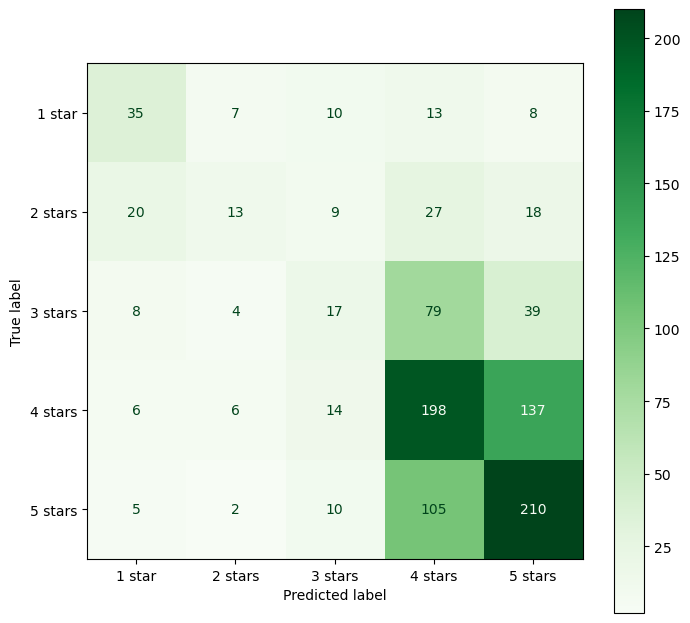

In [42]:
# Confusion matrix
fig, ax = plt.subplots(figsize=(8,8), dpi=100)
ConfusionMatrixDisplay.from_estimator(pipe, X_test, y_test, cmap='Greens', ax=ax);

#### One more...

In [411]:
# Columntransformer


In [412]:
# Pipeline (no tfidf)


In [7]:
# Fit 


In [ ]:
# Score


Slightly less overfit.

In [12]:
# Classification report

# Print the report


In [13]:
# Confusion matrix


#### Feature importances

In [14]:
# Column names

# Coefs

# Why do I have 5 lists of coefs? Because I have 5 classes.

In [15]:
# 5 star reviews

# add sentiment score to my array of features


In [16]:
# Most predictive of 5 star review


In [17]:
# Most predictive of 1 star review


You can't interpret these like regular coefs! Instead you can talk about relative importance.

In [18]:
# What if I want to aggregate my predictions from multiple models?

# 'hard' for majority voting, 'soft' for averaging predicted probabilities.


#### Next steps...
- Gridsearch
- Text preprocessing functions
- Try new models (coming soon!)